   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 97.1/97.1 MB 42.0 MB/s  0:00:02
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7.9/7.9 MB 75.7 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2/2 [catboost]
             5개 도시 관광객 수 예측 모델 성과 비교
                 Model  R² (설명력)   MAE (평균오차)         RMSE
            OLS (선형회귀)  0.699323 12318.089224 18314.369659
         Random Forest  0.760576 10028.556564 16342.770076
              CatBoost  0.872419  6985.767880 11929.841431
              LightGBM  0.850069  7809.129333 12932.653642
               XGBoost  0.865434  7086.964355 12252.101860
★ 최종 앙상블 (Cat+LGB+XGB)  0.870698  6970.036543 12010.062556


/tmp/ipykernel_3377/3072195326.py:105: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=results_df, x='Model', y='R² (설명력)', ax=axes[0], palette='Set2')
/tmp/ipykernel_3377/3072195326.py:117: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=results_df, x='Model', y='MAE (평균오차)', ax=axes[1], palette='Blues_r')
/tmp/ipykernel_3377/3072195326.py:129: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=feature_imp.values, y=feature_imp.index, ax=axes[2], palette='viridis')


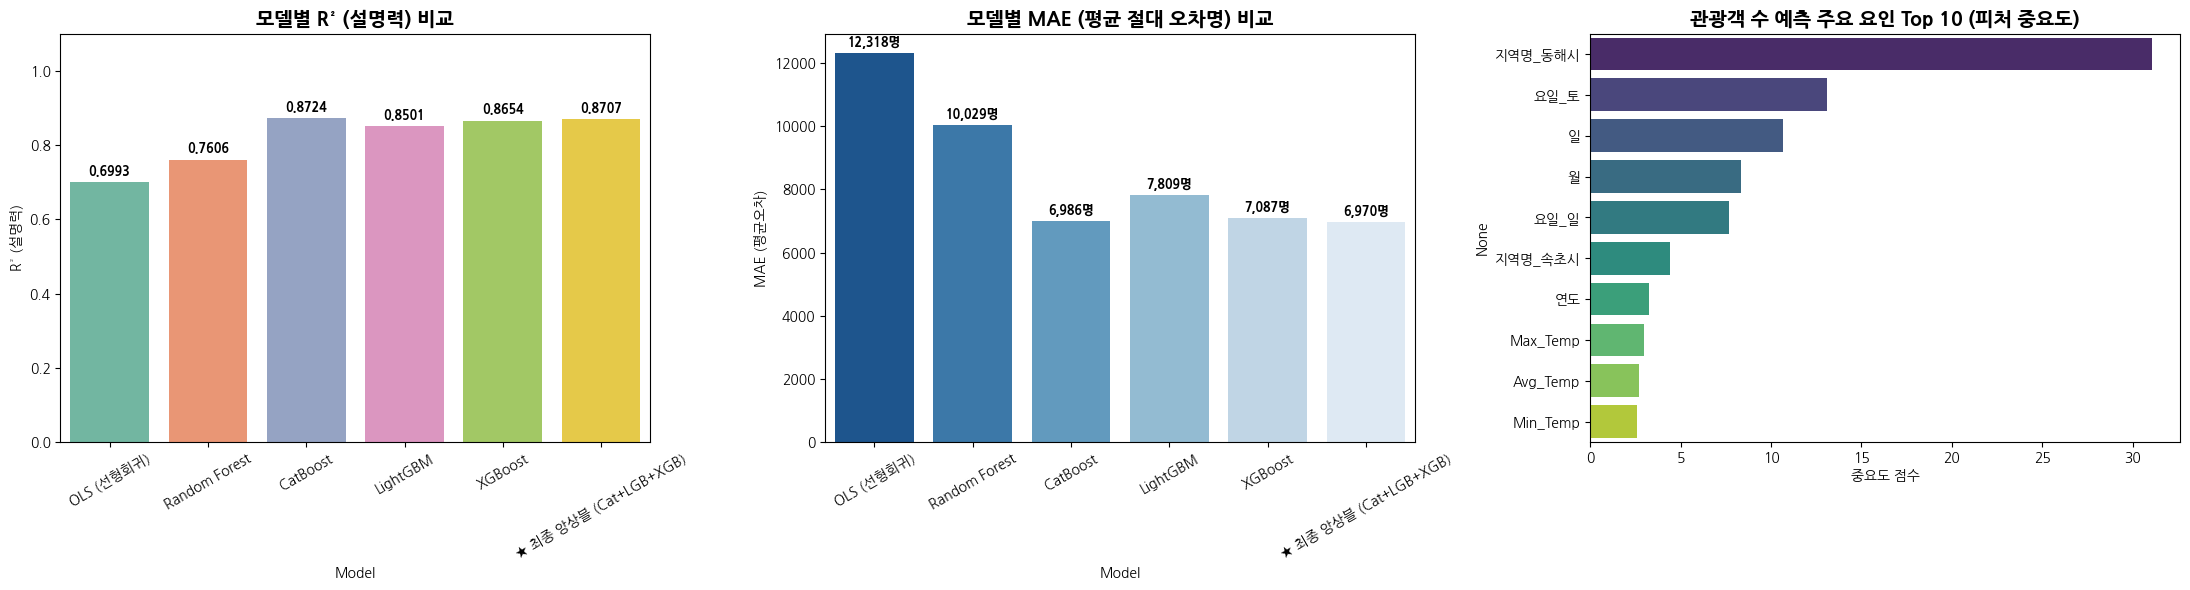


[최종 모델 예측 샘플 테스트]
 실제 방문자수  최종 모델 예측값  오차(명)
   47761      57178   9417
   66392      75694   9302
   73318      84529  11211
   76311      78443   2132
   55195      48222   6973


In [ ]:
!pip install catboost lightgbm xgboost koreanize-matplotlib

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import koreanize_matplotlib

from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from catboost import CatBoostRegressor
from lightgbm import LGBMRegressor, early_stopping
from xgboost import XGBRegressor
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

# 1. 데이터 불러오기
file_path = '/content/강원_관광지_5개_도시_원핫인코딩_완료.csv'
df = pd.read_csv(file_path)

# 2. Feature(X)와 Target(y) 분리
X = df.drop(columns=['날짜', '방문자수(외지인)'])
y = df['방문자수(외지인)']

# 3. Train / Test 데이터 분할 (80:20)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# 선형모델 및 전통 ML용 결측치 평균 대체 데이터셋
X_train_filled = X_train.fillna(X_train.mean())
X_test_filled = X_test.fillna(X_train.mean())

# ---------------------------------------------------------
# [1] 개별 베이스 모델 학습
# ---------------------------------------------------------
# 1) OLS (선형회귀)
ols_model = LinearRegression()
ols_model.fit(X_train_filled, y_train)

# 2) Random Forest
rf_model = RandomForestRegressor(n_estimators=300, max_depth=10, random_state=42, n_jobs=-1)
rf_model.fit(X_train_filled, y_train)

# 3) CatBoost
cat_model = CatBoostRegressor(
    iterations=1000, learning_rate=0.05, depth=6, loss_function='RMSE', random_seed=42, verbose=0
)
cat_model.fit(X_train, y_train, eval_set=(X_test, y_test), early_stopping_rounds=50)

# 4) LightGBM
lgbm_model = LGBMRegressor(
    n_estimators=1000, learning_rate=0.05, max_depth=6, random_state=42, verbose=-1
)
lgbm_model.fit(X_train, y_train, eval_set=[(X_test, y_test)], callbacks=[early_stopping(stopping_rounds=50, verbose=False)])

# 5) XGBoost
xgb_model = XGBRegressor(
    n_estimators=1000, learning_rate=0.05, max_depth=6, random_state=42, early_stopping_rounds=50, tree_method='hist'
)
xgb_model.fit(X_train, y_train, eval_set=[(X_test, y_test)], verbose=False)

# ---------------------------------------------------------
# [2] 예측 수행 및 최종 앙상블(Soft Voting) 구축
# ---------------------------------------------------------
y_pred_ols = ols_model.predict(X_test_filled)
y_pred_rf = rf_model.predict(X_test_filled)
y_pred_cat = cat_model.predict(X_test)
y_pred_lgbm = lgbm_model.predict(X_test)
y_pred_xgb = xgb_model.predict(X_test)

# 최종 앙상블 모델: 성능 우수 3종 가중 결합 (CatBoost 40% + LightGBM 30% + XGBoost 30%)
y_pred_ensemble = (y_pred_cat * 0.4) + (y_pred_lgbm * 0.3) + (y_pred_xgb * 0.3)

# ---------------------------------------------------------
# [3] 성과 평가 및 비교 표 생성
# ---------------------------------------------------------
def get_metrics(y_true, y_pred, model_name):
    r2 = r2_score(y_true, y_pred)
    mae = mean_absolute_error(y_true, y_pred)
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    return {'Model': model_name, 'R² (설명력)': r2, 'MAE (평균오차)': mae, 'RMSE': rmse}

results_df = pd.DataFrame([
    get_metrics(y_test, y_pred_ols, 'OLS (선형회귀)'),
    get_metrics(y_test, y_pred_rf, 'Random Forest'),
    get_metrics(y_test, y_pred_cat, 'CatBoost'),
    get_metrics(y_test, y_pred_lgbm, 'LightGBM'),
    get_metrics(y_test, y_pred_xgb, 'XGBoost'),
    get_metrics(y_test, y_pred_ensemble, '★ 최종 앙상블 (Cat+LGB+XGB)')
])

print("="*65)
print("             5개 도시 관광객 수 예측 모델 성과 비교")
print("="*65)
print(results_df.to_string(index=False))
print("="*65)

# ---------------------------------------------------------
# [4] 종합 시각화 (설명력 / 오차 수치 / 피처 중요도)
# ---------------------------------------------------------
fig, axes = plt.subplots(1, 3, figsize=(22, 6))

# 1. R² (설명력) 비교 차트
sns.barplot(data=results_df, x='Model', y='R² (설명력)', ax=axes[0], palette='Set2')
axes[0].set_title('모델별 R² (설명력) 비교', fontsize=14, fontweight='bold')
axes[0].set_ylim(0, 1.1)
axes[0].tick_params(axis='x', rotation=30)

for p in axes[0].patches:
    height = p.get_height()
    if not np.isnan(height):
        axes[0].annotate(f'{height:.4f}', (p.get_x() + p.get_width() / 2., height),
                         ha='center', va='bottom', fontsize=9, fontweight='bold', xytext=(0, 3), textcoords='offset points')

# 2. MAE 오차 수치 비교 차트
sns.barplot(data=results_df, x='Model', y='MAE (평균오차)', ax=axes[1], palette='Blues_r')
axes[1].set_title('모델별 MAE (평균 절대 오차명) 비교', fontsize=14, fontweight='bold')
axes[1].tick_params(axis='x', rotation=30)

for p in axes[1].patches:
    height = p.get_height()
    if not np.isnan(height) and height > 0:
        axes[1].annotate(f'{height:,.0f}명', (p.get_x() + p.get_width() / 2., height),
                         ha='center', va='bottom', fontsize=9, fontweight='bold', xytext=(0, 3), textcoords='offset points')

# 3. 주요 피처 중요도 Top 10 (CatBoost 기준)
feature_imp = pd.Series(cat_model.get_feature_importance(), index=X.columns).sort_values(ascending=False).head(10)
sns.barplot(x=feature_imp.values, y=feature_imp.index, ax=axes[2], palette='viridis')
axes[2].set_title('관광객 수 예측 주요 요인 Top 10 (피처 중요도)', fontsize=14, fontweight='bold')
axes[2].set_xlabel('중요도 점수')

plt.tight_layout()
plt.show()

# ---------------------------------------------------------
# [5] 신규 데이터 관광객 수 예측 추론 함수
# ---------------------------------------------------------
def predict_tourist_count(input_df):
    """
    입력 데이터프레임을 받아 최종 앙상블 모델로 관광객 수를 예측합니다.
    """
    pred_cat = cat_model.predict(input_df)
    pred_lgbm = lgbm_model.predict(input_df)
    pred_xgb = xgb_model.predict(input_df)

    final_pred = (pred_cat * 0.4) + (pred_lgbm * 0.3) + (pred_xgb * 0.3)
    return final_pred

# 테스트 데이터 샘플 5건 예측 수행 예시
sample_predictions = predict_tourist_count(X_test.head(5))
sample_result = pd.DataFrame({
    '실제 방문자수': y_test.head(5).values,
    '최종 모델 예측값': np.round(sample_predictions).astype(int),
    '오차(명)': np.abs(y_test.head(5).values - np.round(sample_predictions).astype(int))
})

print("\n[최종 모델 예측 샘플 테스트]")
print(sample_result.to_string(index=False))